# Практика: Влияние инициализации и скорости обучения на MNIST

В этом практическом занятии мы исследуем, как начальная инициализация весов и скорость обучения влияют на обучение нейронной сети на реальном наборе данных MNIST (рукописные цифры). Мы будем использовать простую полносвязную сеть (MLP) с двумя скрытыми слоями.

**Цели:**
- Научиться загружать и подготавливать данные MNIST.
- Сравнить различные инициализации (по умолчанию, Xavier, He, случайная большая).
- Исследовать влияние скорости обучения на сходимость.
- Визуализировать процесс обучения и полученные признаки.

**Задание: повторить все действия и сделать выводы для набора данных Fashion-MNIST.**

> **Выполнил:** Подольский Филипп, магистратура ПМИ, ФМИ ПГНИУ.
>
> **Задание выполнено на Fashion-MNIST**: все шаги тетрадки повторены без изменения логики и параметров (та же сеть
> 784–256–128–10, SGD, 5 эпох, первые 10 000 обучающих и 2 000 тестовых изображений, те же инициализации и
> скорости обучения); поменялись только набор данных (`torchvision.datasets.FashionMNIST`), нормировка (среднее и
> стандартное отклонение Fashion-MNIST) и подписи классов. Ответы на вопросы и выводы — после соответствующих
> графиков, в конце — сравнение с MNIST на том же коде.
>
> Первая ячейка кода — общие настройки запуска (устройство cuda → mps → cpu, данные в `../data`); в функцию
> обучения добавлен перенос модели и батчей на выбранное устройство.

In [1]:
%matplotlib inline
# ── Настройки запуска (добавлено при выполнении работы) ──────────────────────────────────────────
# Устройство: cuda -> mps -> cpu. Режим быстрой проверки NN_SMOKE=1: крошечные подвыборки и 1 эпоха
# (в обычном запуске — параметры из задания). Данные и кэши моделей — в папке ../data.
import os
os.environ.setdefault('PYTORCH_ENABLE_MPS_FALLBACK', '1')   # операции, которых нет в MPS, выполняются на CPU
SMOKE = os.environ.get('NN_SMOKE') == '1'
DATA = '../data'
os.makedirs(DATA, exist_ok=True)
os.environ.setdefault('TORCH_HOME', os.path.abspath(os.path.join(DATA, 'torch_cache')))   # веса torchvision
os.environ.setdefault('HF_HOME', os.path.abspath(os.path.join(DATA, 'hf_cache')))         # модели и датасеты HuggingFace

import torch

def get_device():
    """cuda -> mps -> cpu; переменной окружения NN_DEVICE устройство можно задать явно (например, NN_DEVICE=cpu)."""
    if os.environ.get('NN_DEVICE'):
        return torch.device(os.environ['NN_DEVICE'])
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')

def S(full, smoke):
    """Параметр запуска: значение из задания (full) или уменьшенное для проверки NN_SMOKE=1 (smoke)."""
    return smoke if SMOKE else full

device = get_device()
print(f'Устройство: {device} | режим: {"быстрая проверка (NN_SMOKE=1)" if SMOKE else "полный запуск"}')

Устройство: mps | режим: полный запуск


In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import numpy as np
import matplotlib.pyplot as plt
import contextlib, io


# Фиксируем seed для воспроизводимости
torch.manual_seed(42)
np.random.seed(42)

## 1. Загрузка и предобработка данных MNIST

Загрузим обучающую и тестовую выборки, нормализуем изображения и создадим DataLoader'ы. Для ускорения эксперимента возьмём только первые 10000 обучающих примеров и 2000 тестовых.

**Здесь — Fashion-MNIST** (по заданию): берём первые 10 000 обучающих и 2 000 тестовых изображений. Ниже сохранена схема преподавателя (слои и размеры тензоров для MNIST — у Fashion-MNIST они те же: 28×28, 10 классов).

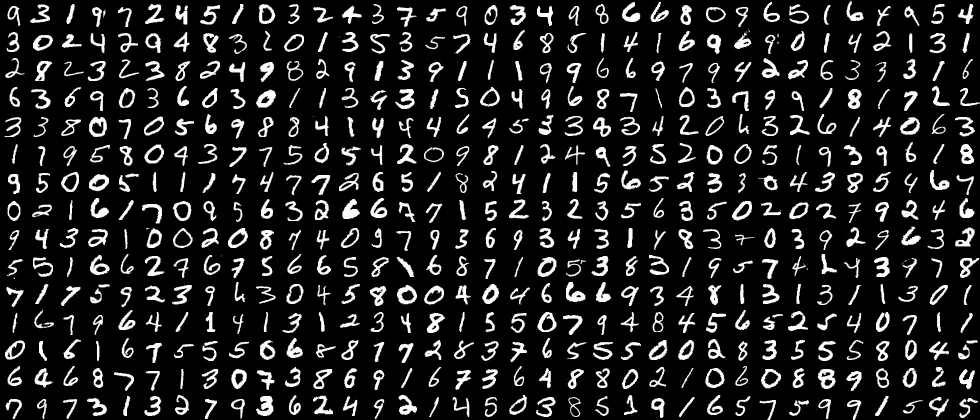

In [3]:
CLASSES = ['футболка', 'брюки', 'свитер', 'платье', 'пальто', 'сандалии', 'рубашка', 'кроссовки', 'сумка', 'ботинки']

# Среднее и стандартное отклонение пикселей Fashion-MNIST посчитаем по обучающей выборке
raw = datasets.FashionMNIST(root=DATA, train=True, download=True).data.float() / 255
fmnist_mean, fmnist_std = raw.mean().item(), raw.std().item()
print(f'среднее = {fmnist_mean:.4f}, std = {fmnist_std:.4f} (у MNIST было 0.1307 и 0.3081)')

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((fmnist_mean,), (fmnist_std,))  # среднее и std для Fashion-MNIST
])

train_dataset = datasets.FashionMNIST(root=DATA, train=True, download=True, transform=transform)
test_dataset = datasets.FashionMNIST(root=DATA, train=False, download=True, transform=transform)

# Ограничим выборку для быстроты
train_dataset = torch.utils.data.Subset(train_dataset, range(S(10000, 512)))
test_dataset = torch.utils.data.Subset(test_dataset, range(S(2000, 256)))

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

labels_train = np.array([train_dataset.dataset.targets[i].item() for i in range(len(train_dataset))])
print('объектов в обучающей подвыборке по классам:', np.bincount(labels_train).tolist())

среднее = 0.2860, std = 0.3530 (у MNIST было 0.1307 и 0.3081)
объектов в обучающей подвыборке по классам: [942, 1027, 1016, 1019, 974, 989, 1021, 1022, 990, 1000]


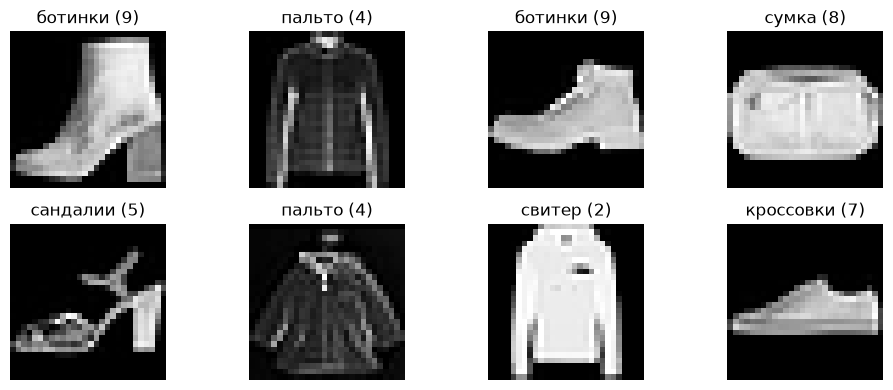

In [4]:
# Посмотрим на несколько изображений
images, labels = next(iter(train_loader))
plt.figure(figsize=(10,4))
for i in range(8):
    plt.subplot(2,4,i+1)
    plt.imshow(images[i][0], cmap='gray')
    plt.title(f'{CLASSES[labels[i].item()]} ({labels[i].item()})')
    plt.axis('off')
plt.tight_layout()
plt.show()

## 2. Определение модели

Создадим MLP с двумя скрытыми слоями (256 и 128 нейронов) и выходным слоем на 10 классов (softmax не включаем, так как будем использовать CrossEntropyLoss).

In [5]:
class MLP(nn.Module):
    def __init__(self, input_size=784, hidden1=256, hidden2=128, output_size=10):
        super(MLP, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden1)
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Linear(hidden1, hidden2)
        self.relu2 = nn.ReLU()
        self.fc3 = nn.Linear(hidden2, output_size)
        # без softmax, его добавит loss

    def forward(self, x):
        x = x.view(x.size(0), -1)  # вытягиваем изображения в вектор
        x = self.relu1(self.fc1(x))
        x = self.relu2(self.fc2(x))
        x = self.fc3(x)
        return x

def init_weights(m, mode='default'):
    if isinstance(m, nn.Linear):
        if mode == 'normal':
            nn.init.normal_(m.weight, mean=0, std=1.0)
            nn.init.zeros_(m.bias)
        elif mode == 'xavier':
            nn.init.xavier_normal_(m.weight)
            nn.init.zeros_(m.bias)
        elif mode == 'he':
            nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
            nn.init.zeros_(m.bias)
        elif mode == 'default':
            pass  # оставляем умолчательную

## 3. Функция для обучения и оценки

Определим функцию, которая принимает модель, загрузчики, число эпох, скорость обучения и тип инициализации, обучает и возвращает историю потерь и точности.

In [6]:
def train_and_evaluate(model, train_loader, test_loader, epochs=5, lr=0.01, init_mode='default'):
    model.apply(lambda m: init_weights(m, init_mode))
    model.to(device)                      # обучение на выбранном устройстве (cuda/mps/cpu)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=lr)

    # Пустые массивы для накопления истории обучения
    train_losses = []
    test_losses = []
    train_accs = []
    test_accs = []

    for epoch in range(epochs):
        # Это только перевод в режим обучения
        model.train()
        running_loss = 0.0
        correct_train = 0
        total_train = 0

        # Перебор всех данных из обучающей выборки
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            # Прямой проход
            outputs = model(images)
            # Текущее значение функции потерь
            loss = criterion(outputs, labels)
            # Обратное распространение ошибки.
            loss.backward()

            # обновление весов модели на основе градиентов.
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            total_train += labels.size(0)
            correct_train += (predicted == labels).sum().item()

        # Обновление метрик после прохода всех данных
        epoch_train_loss = running_loss / len(train_loader.dataset)
        epoch_train_acc = correct_train / total_train
        train_losses.append(epoch_train_loss)
        train_accs.append(epoch_train_acc)

        # Оценка на тесте
        model.eval()
        test_loss = 0.0
        correct_test = 0
        total_test = 0
        with torch.no_grad():
            for images, labels in test_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)
                test_loss += loss.item() * images.size(0)
                _, predicted = torch.max(outputs, 1)
                total_test += labels.size(0)
                correct_test += (predicted == labels).sum().item()

        epoch_test_loss = test_loss / len(test_loader.dataset)
        epoch_test_acc = correct_test / total_test
        test_losses.append(epoch_test_loss)
        test_accs.append(epoch_test_acc)

        print(f'Epoch {epoch+1}/{epochs} | Train Loss: {epoch_train_loss:.4f} | Test Loss: {epoch_test_loss:.4f} | Test Acc: {epoch_test_acc:.4f}')

    return train_losses, test_losses, train_accs, test_accs

## 4. Эксперимент 1: Сравнение инициализаций

Зафиксируем скорость обучения `lr = 0.01` и сравним четыре инициализации: по умолчанию, Xavier, He, случайная нормальная с большой дисперсией (std=1). Обучим каждую модель в течение 5 эпох.

In [7]:
init_modes = ['default', 'xavier', 'he', 'normal']
histories = {}

for mode in init_modes:
    print(f"\n=== Инициализация: {mode} ===")
    model = MLP()
    train_loss, test_loss, train_acc, test_acc = train_and_evaluate(
        model, train_loader, test_loader, epochs=S(5, 1), lr=0.01, init_mode=mode
    )
    histories[mode] = {
        'train_loss': train_loss,
        'test_loss': test_loss,
        'train_acc': train_acc,
        'test_acc': test_acc,
        'model': model
    }


=== Инициализация: default ===


Epoch 1/5 | Train Loss: 1.7739 | Test Loss: 1.1853 | Test Acc: 0.6200


Epoch 2/5 | Train Loss: 0.9479 | Test Loss: 0.8296 | Test Acc: 0.6990


Epoch 3/5 | Train Loss: 0.7343 | Test Loss: 0.6928 | Test Acc: 0.7565


Epoch 4/5 | Train Loss: 0.6431 | Test Loss: 0.6651 | Test Acc: 0.7265


...

Epoch 1/5 | Train Loss: 186.3587 | Test Loss: 10.8159 | Test Acc: 0.5100


Epoch 2/5 | Train Loss: 7.5311 | Test Loss: 6.2714 | Test Acc: 0.4655


Epoch 3/5 | Train Loss: 3.7247 | Test Loss: 5.8765 | Test Acc: 0.4085


Epoch 4/5 | Train Loss: 2.6679 | Test Loss: 4.5037 | Test Acc: 0.4625


Epoch 5/5 | Train Loss: 2.0989 | Test Loss: 4.1837 | Test Acc: 0.4605


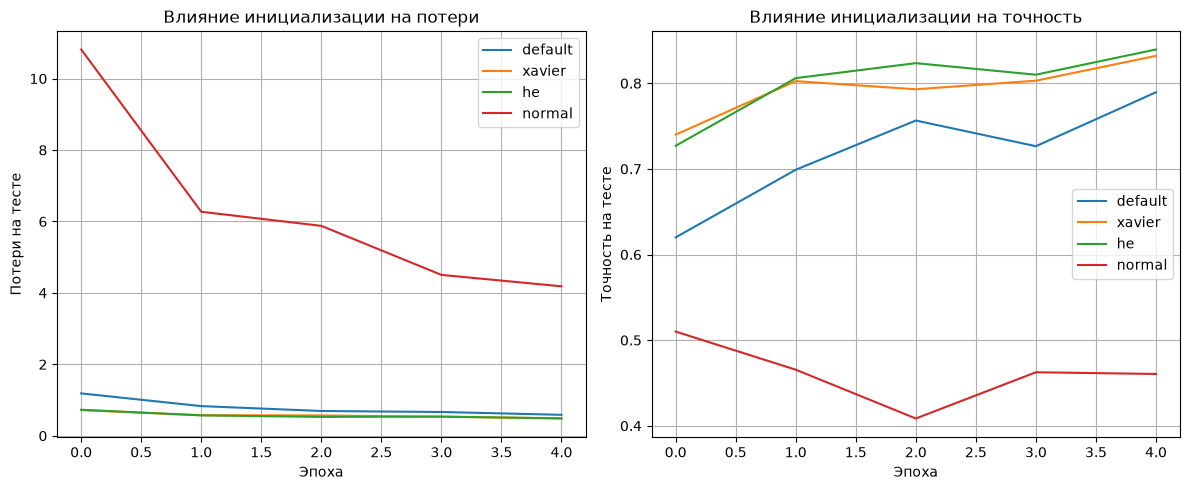

In [8]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
for mode in init_modes:
    plt.plot(histories[mode]['test_loss'], label=mode)
plt.xlabel('Эпоха')
plt.ylabel('Потери на тесте')
plt.title('Влияние инициализации на потери')
plt.legend()
plt.grid(True)

plt.subplot(1,2,2)
for mode in init_modes:
    plt.plot(histories[mode]['test_acc'], label=mode)
plt.xlabel('Эпоха')
plt.ylabel('Точность на тесте')
plt.title('Влияние инициализации на точность')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [9]:
# Сводка эксперимента 1: итоговые метрики и разрыв между обучением и тестом
print(f"{'инициализация':<14} {'train loss':>10} {'test loss':>10} {'train acc':>10} {'test acc':>9}")
for mode in init_modes:
    h = histories[mode]
    print(f"{mode:<14} {h['train_loss'][-1]:>10.4f} {h['test_loss'][-1]:>10.4f} {h['train_acc'][-1]:>10.4f} {h['test_acc'][-1]:>9.4f}")

# Почему 'normal' плох: масштаб сигналов в сети сразу после инициализации (до обучения)
x_batch, _ = next(iter(train_loader))
for mode in init_modes:
    torch.manual_seed(0)
    m = MLP(); m.apply(lambda mm: init_weights(mm, mode))
    with torch.no_grad():
        h1 = m.relu1(m.fc1(x_batch.view(len(x_batch), -1)))
        h2 = m.relu2(m.fc2(h1))
        out = m.fc3(h2)
    print(f"{mode:<8} std активаций: слой 1 = {h1.std():8.2f}, слой 2 = {h2.std():9.2f}, логиты = {out.std():9.2f}, "
          f"начальная потеря = {nn.functional.cross_entropy(out, _).item():9.2f}")

инициализация  train loss  test loss  train acc  test acc
default            0.5907     0.5854     0.7868    0.7895
xavier             0.4471     0.4900     0.8411    0.8320
he                 0.4366     0.4828     0.8444    0.8395
normal             2.0989     4.1837     0.4774    0.4605
default  std активаций: слой 1 =     0.33, слой 2 =      0.13, логиты =      0.10, начальная потеря =      2.33
xavier   std активаций: слой 1 =     0.68, слой 2 =      0.56, логиты =      0.84, начальная потеря =      2.62
he       std активаций: слой 1 =     0.78, слой 2 =      0.80, логиты =      1.23, начальная потеря =      2.98
normal   std активаций: слой 1 =    15.53, слой 2 =    178.23, логиты =   2196.38, начальная потеря =   3740.18


**Вопросы для анализа:**
- Какая инициализация обеспечила наилучшую точность?
- Почему инициализация 'normal' (std=1) работает хуже?
- Соответствуют ли результаты теоретическим ожиданиям (He лучше для ReLU)?

Итог после 5 эпох (`lr = 0.01`):

| инициализация | train loss | test loss | train acc | test acc |
|---|---|---|---|---|
| по умолчанию (PyTorch) | 0,591 | 0,585 | 0,787 | 0,790 |
| Xavier | 0,447 | 0,490 | 0,841 | 0,832 |
| He | 0,437 | 0,483 | 0,844 | **0,840** |
| normal, std = 1 | 2,099 | 4,184 | 0,477 | 0,461 |

- **Лучшая точность у He:** 0,840 на тесте. Xavier почти рядом (0,832): разница 0,75 п. п., то есть 15 картинок из 2000, и на одном запуске её нельзя считать надёжной. Обе инициализации заметно лучше варианта по умолчанию (0,790). Инициализация по умолчанию уменьшает сигнал от слоя к слою: std активаций 0,33 → 0,13 → 0,10. Сеть стартует почти с нулевыми логитами и при `lr = 0.01` медленнее «раскачивается».
- **`normal` (std = 1) хуже всех**, потому что веса слишком большие для слоя с 784 входами. Каждый нейрон суммирует сотни слагаемых с дисперсией 1, и сигнал растёт от слоя к слою: std активаций 15,5 → 178 → 2196 на логитах. Начальная потеря 3740, тогда как у остальных вариантов она 2,3–3,0 (близко к $\ln 10 \approx 2{,}3$ — потере при равномерном угадывании). Огромные логиты дают огромные градиенты: в первую эпоху train loss = 186. За 5 эпох сеть так и не выходит на нормальный режим: точность 0,46, test loss 4,18 при train loss 2,10.
- **С теорией результат согласуется.** He рассчитана на ReLU: масштаб $\sqrt{2/n_{in}}$ компенсирует то, что ReLU обнуляет примерно половину сигнала. Здесь std активаций у He держится около 0,8 на обоих скрытых слоях, а у Xavier снижается (0,68 → 0,56). По точности He впереди, но с небольшим отрывом: в сети всего с двумя скрытыми слоями это затухание у Xavier пока мало влияет.

## 5. Эксперимент 2: Влияние скорости обучения

Теперь зафиксируем инициализацию He (как лучшую для ReLU) и сравним три значения скорости обучения: 0.001, 0.01, 0.1.

In [10]:
lrs = [0.001, 0.01, 0.1]
lr_histories = {}

for lr in lrs:
    print(f"\n=== Learning rate: {lr} ===")
    model = MLP()
    train_loss, test_loss, train_acc, test_acc = train_and_evaluate(
        model, train_loader, test_loader, epochs=S(5, 1), lr=lr, init_mode='he'
    )
    lr_histories[lr] = {
        'train_loss': train_loss,
        'test_loss': test_loss,
        'train_acc': train_acc,
        'test_acc': test_acc,
        'model': model
    }


=== Learning rate: 0.001 ===


Epoch 1/5 | Train Loss: 1.9330 | Test Loss: 1.3745 | Test Acc: 0.5665


Epoch 2/5 | Train Loss: 1.1805 | Test Loss: 1.0513 | Test Acc: 0.6575


Epoch 3/5 | Train Loss: 0.9665 | Test Loss: 0.9122 | Test Acc: 0.6990


Epoch 4/5 | Train Loss: 0.8631 | Test Loss: 0.8350 | Test Acc: 0.7240


...

Epoch 1/5 | Train Loss: 0.6896 | Test Loss: 1.0186 | Test Acc: 0.6540


Epoch 2/5 | Train Loss: 0.4600 | Test Loss: 0.4953 | Test Acc: 0.8265


Epoch 3/5 | Train Loss: 0.3864 | Test Loss: 0.5314 | Test Acc: 0.8095


Epoch 4/5 | Train Loss: 0.3438 | Test Loss: 0.6066 | Test Acc: 0.7860


Epoch 5/5 | Train Loss: 0.3093 | Test Loss: 0.4503 | Test Acc: 0.8395


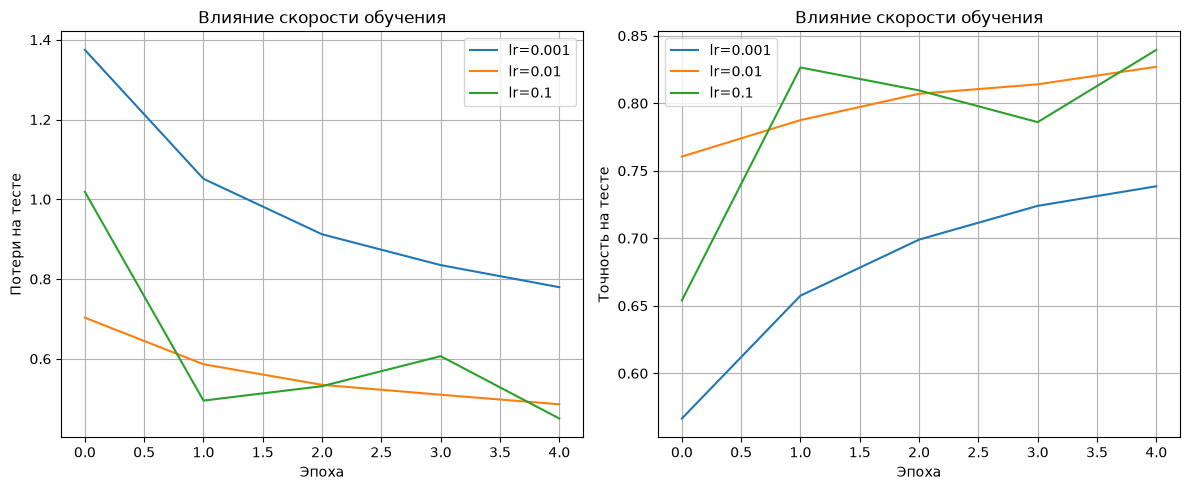

In [11]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
for lr in lrs:
    plt.plot(lr_histories[lr]['test_loss'], label=f'lr={lr}')
plt.xlabel('Эпоха')
plt.ylabel('Потери на тесте')
plt.title('Влияние скорости обучения')
plt.legend()
plt.grid(True)

plt.subplot(1,2,2)
for lr in lrs:
    plt.plot(lr_histories[lr]['test_acc'], label=f'lr={lr}')
plt.xlabel('Эпоха')
plt.ylabel('Точность на тесте')
plt.title('Влияние скорости обучения')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

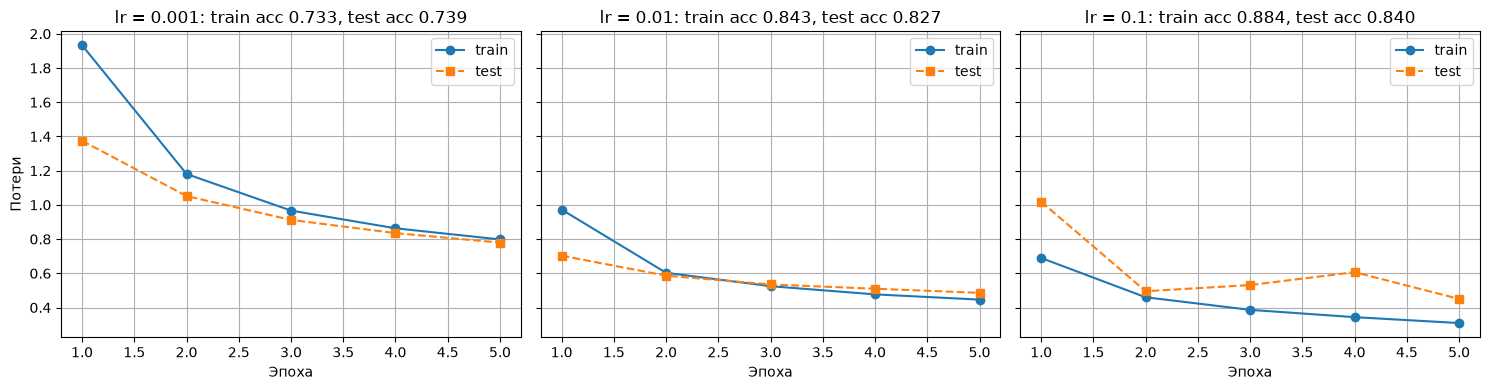


=== Learning rate: 0.5 ===


Epoch 1/5 | Train Loss: nan | Test Loss: nan | Test Acc: 0.1000


Epoch 2/5 | Train Loss: nan | Test Loss: nan | Test Acc: 0.1000


Epoch 3/5 | Train Loss: nan | Test Loss: nan | Test Acc: 0.1000


Epoch 4/5 | Train Loss: nan | Test Loss: nan | Test Acc: 0.1000


...

Epoch 1/5 | Train Loss: nan | Test Loss: nan | Test Acc: 0.1000


Epoch 2/5 | Train Loss: nan | Test Loss: nan | Test Acc: 0.1000


Epoch 3/5 | Train Loss: nan | Test Loss: nan | Test Acc: 0.1000


Epoch 4/5 | Train Loss: nan | Test Loss: nan | Test Acc: 0.1000


Epoch 5/5 | Train Loss: nan | Test Loss: nan | Test Acc: 0.1000


In [12]:
# Переобучение / недообучение: потери на обучении и тесте для каждого lr
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, lr in zip(axes, lrs):
    h = lr_histories[lr]
    ep = range(1, len(h['train_loss']) + 1)
    ax.plot(ep, h['train_loss'], 'o-', label='train')
    ax.plot(ep, h['test_loss'], 's--', label='test')
    ax.set_title(f'lr = {lr}: train acc {h["train_acc"][-1]:.3f}, test acc {h["test_acc"][-1]:.3f}')
    ax.set_xlabel('Эпоха'); ax.grid(True); ax.legend()
axes[0].set_ylabel('Потери')
plt.tight_layout()
plt.show()

# Что будет при lr = 1.0 (и промежуточном 0.5)
for lr in [0.5, 1.0]:
    print(f"\n=== Learning rate: {lr} ===")
    torch.manual_seed(42)
    model = MLP()
    tr_l, te_l, tr_a, te_a = train_and_evaluate(model, train_loader, test_loader, epochs=S(5, 1), lr=lr, init_mode='he')
    lr_histories[lr] = {'train_loss': tr_l, 'test_loss': te_l, 'train_acc': tr_a, 'test_acc': te_a, 'model': model}

**Вопросы:**
- Какое значение learning rate дало наилучший результат?
- Наблюдается ли переобучение или недообучение при каком-либо lr?
- Что произойдёт, если взять lr = 1.0? (можно проверить самостоятельно)

Итог после 5 эпох (инициализация He):

| lr | train loss | test loss | train acc | test acc |
|---|---|---|---|---|
| 0,001 | 0,798 | 0,780 | 0,733 | 0,739 |
| 0,01 | 0,446 | 0,486 | 0,843 | 0,827 |
| 0,1 | 0,309 | 0,450 | 0,884 | **0,840** |
| 0,5 | nan | nan | — | 0,100 |
| 1,0 | nan | nan | — | 0,100 |

- **Лучший результат на 5-й эпохе — у `lr = 0.1`**: test acc 0,840 и наименьший test loss 0,450. Но обучение у него неровное: test loss по эпохам 1,02 → 0,50 → 0,53 → 0,61 → 0,45, а точность в середине падала с 0,827 до 0,786 и снова выросла. `lr = 0.01` даёт почти ту же точность (0,827) при плавно убывающих кривых. Поэтому надёжнее либо `lr = 0.01`, либо 0,1 с уменьшением шага по ходу обучения.
- **Недообучение — при `lr = 0.001`.** Обе потери высокие (0,80 и 0,78) и ещё заметно падают на 5-й эпохе, train и test почти совпадают. Модель просто не успела обучиться.
- **Переобучение.** При 0,001 и 0,01 его нет: train и test accuracy почти равны (0,733/0,739 и 0,843/0,827). У `lr = 0.1` разрыв уже 4,4 п. п. (0,884 против 0,840): train loss монотонно падает до 0,31, а test loss скачет между 0,45 и 0,61. Это признак начинающегося переобучения.
- **`lr = 1.0`, и уже `0.5`**: обучение разваливается в первую же эпоху. Потери становятся `nan`, точность 0,100 — это угадывание одного класса из десяти. Шаг настолько большой, что веса за несколько итераций уходят в бесконечность, и дальше все вычисления дают `nan`.

## 6. Визуализация весов первого слоя

Для лучшей модели (например, He + lr=0.01) визуализируем веса первого слоя как изображения 28x28, чтобы увидеть, какие паттерны выучили нейроны.

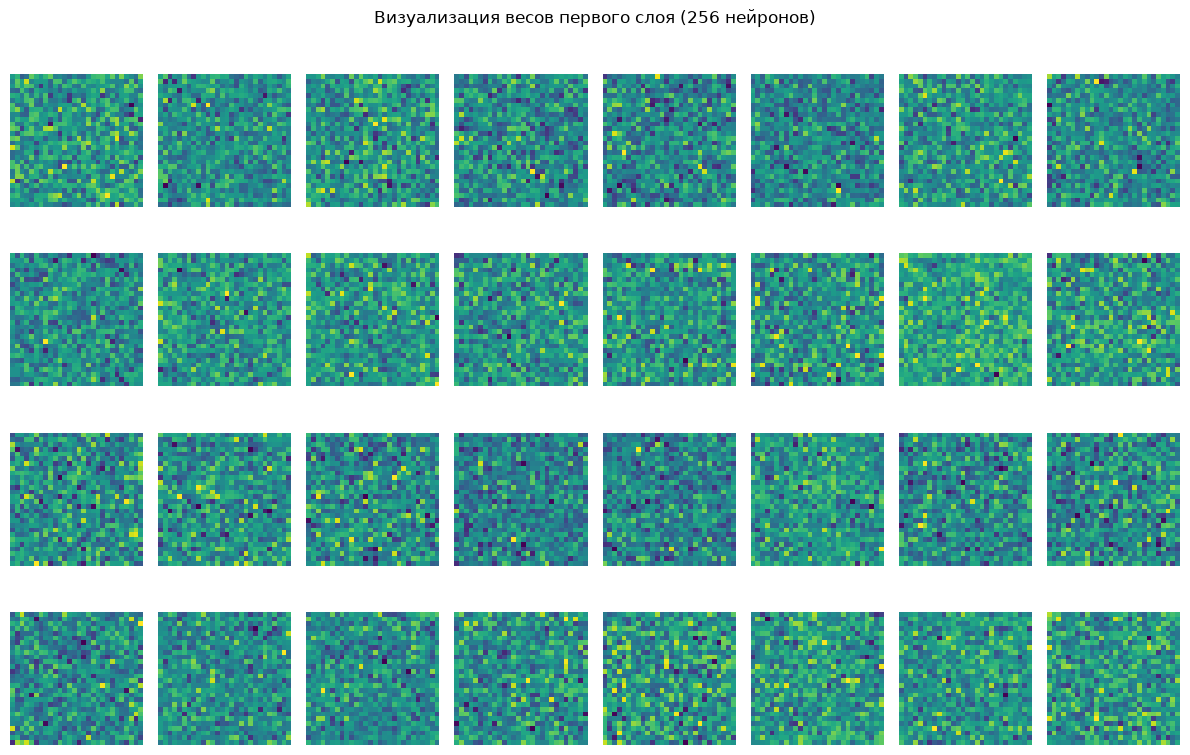

In [13]:
best_model = histories['he']['model']  # из первого эксперимента
weights = best_model.fc1.weight.detach().cpu().numpy()  # (256, 784)

# Отобразим первые 32 нейрона
plt.figure(figsize=(12,8))
for i in range(32):
    plt.subplot(4,8,i+1)
    w = weights[i].reshape(28,28)
    plt.imshow(w, cmap='viridis')
    plt.axis('off')
plt.suptitle('Визуализация весов первого слоя (256 нейронов)')
plt.tight_layout()
plt.show()

точность на тесте: 0.8085
||W_до|| = 22.57, ||dW|| = 4.62  -> изменение составляет 20% от нормы начальных весов
число нейронов, сильнее всего реагирующих на класс: {'футболка': 24, 'брюки': 50, 'свитер': 15, 'платье': 11, 'пальто': 7, 'сандалии': 45, 'рубашка': 5, 'кроссовки': 32, 'сумка': 29, 'ботинки': 38}


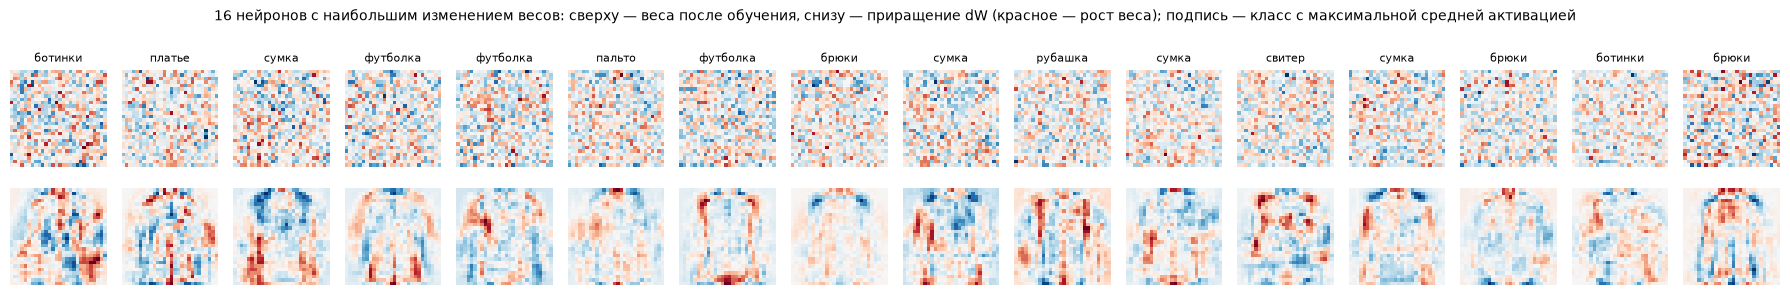

In [14]:
# Дополнительно. Веса на картинках выше — сумма случайной инициализации и того, что сеть выучила за 5 эпох.
# Чтобы отделить выученное от начального шума, обучим такую же сеть (He, lr = 0.1), запомнив веса до обучения,
# нарисуем приращение весов dW = W_после - W_до и посчитаем, какую долю нормы начальных весов оно составляет.
torch.manual_seed(42)
model_vis = MLP()
model_vis.apply(lambda m: init_weights(m, 'he'))
W0 = model_vis.fc1.weight.detach().clone().numpy()
with contextlib.redirect_stdout(io.StringIO()):
    _, _, _, acc_vis = train_and_evaluate(model_vis, train_loader, test_loader, epochs=S(5, 1), lr=0.1, init_mode='default')  # 'default' = без повторной инициализации
W1 = model_vis.fc1.weight.detach().cpu().numpy()
dW = W1 - W0
print(f"точность на тесте: {acc_vis[-1]:.4f}")
print(f"||W_до|| = {np.linalg.norm(W0):.2f}, ||dW|| = {np.linalg.norm(dW):.2f}  -> изменение составляет {np.linalg.norm(dW) / np.linalg.norm(W0):.0%} от нормы начальных весов")

# На какой класс каждый нейрон реагирует сильнее всего (средняя активация на тестовых изображениях класса)
n_test = len(test_dataset)
X_all = torch.stack([test_dataset[i][0] for i in range(n_test)]).view(n_test, -1)
y_all = np.array([test_dataset[i][1] for i in range(n_test)])
with torch.no_grad():
    act = torch.relu(model_vis.fc1(X_all.to(device))).cpu().numpy()          # (2000, 256)
class_mean_act = np.stack([act[y_all == c].mean(0) for c in range(10)])   # (10, 256)
pref = class_mean_act.argmax(0)
print("число нейронов, сильнее всего реагирующих на класс:", {CLASSES[c]: int((pref == c).sum()) for c in range(10)})

order = np.argsort(-np.linalg.norm(dW, axis=1))[:16]
fig, axes = plt.subplots(2, 16, figsize=(18, 3.2))
for k, i in enumerate(order):
    for row, (mat, ttl) in enumerate([(W1, 'W'), (dW, 'dW')]):
        w = mat[i].reshape(28, 28); lim = np.abs(w).max()
        axes[row, k].imshow(w, cmap='RdBu_r', vmin=-lim, vmax=lim)
        axes[row, k].axis('off')
    axes[0, k].set_title(CLASSES[pref[i]], fontsize=8)
fig.suptitle('16 нейронов с наибольшим изменением весов: сверху — веса после обучения, снизу — приращение dW '
             '(красное — рост веса); подпись — класс с максимальной средней активацией', fontsize=10)
plt.tight_layout()
plt.show()

**На первом рисунке** — 32 нейрона модели He с `lr = 0.01`. Веса выглядят как случайный шум, одежды на них не видно. Причина в том, что за 5 эпох веса изменились мало. Для такой же сети с `lr = 0.1` норма приращения $\|dW\| = 4{,}62$ при норме начальных весов $\|W_{до}\| = 22{,}57$: изменение составляет всего 20 % от случайной инициализации. Выученное прячется под шумом начальных весов. Точность этой сети на тесте 0,8085.

**Если нарисовать само приращение** $dW = W_{после} - W_{до}$ (нижний ряд второго рисунка, 16 нейронов с наибольшим изменением весов), появляются силуэты: контуры футболок и платьев с рукавами, брючины, обувь в нижней части кадра, сумки. Красные области — пиксели, которые усиливают активацию нейрона, синие — ослабляют. У многих нейронов на одной картинке есть и красные, и синие силуэты, то есть нейрон реагирует на сочетание признаков, а не на одну вещь целиком.

**По классу, на котором нейрон в среднем активируется сильнее всего**, 256 нейронов распределились неравномерно:

| класс | брюки | сандалии | ботинки | кроссовки | сумка | футболка | свитер | платье | пальто | рубашка |
|---|---|---|---|---|---|---|---|---|---|---|
| нейронов | 50 | 45 | 38 | 32 | 29 | 24 | 15 | 11 | 7 | 5 |

Больше всего нейронов сильнее всего откликаются на брюки и обувь, меньше всего — на пальто и рубашки.

## 7. Выводы

В этом практическом занятии мы:
- Загрузили реальный набор данных MNIST и построили простой MLP.
- Сравнили различные инициализации весов и убедились, что Xavier и He дают лучшую сходимость, чем случайная большая инициализация.
- Исследовали влияние скорости обучения и увидели, что слишком маленький шаг замедляет обучение, а слишком большой может привести к нестабильности.
- Визуализировали веса первого слоя, которые показывают, что нейроны учатся распознавать характерные штрихи цифр.

Эти эксперименты демонстрируют важность правильного выбора гиперпараметров при обучении нейросетей.

## 8. Сравнение с MNIST

Чтобы выводы для Fashion-MNIST были предметными, те же эксперименты (тот же код, те же размеры подвыборок и число эпох) прогнаны на MNIST; ниже — только итоговая точность на тесте после 5 эпох.

In [15]:
mnist_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))])
m_train = torch.utils.data.Subset(datasets.MNIST(root=DATA, train=True, download=True, transform=mnist_tf), range(S(10000, 512)))
m_test = torch.utils.data.Subset(datasets.MNIST(root=DATA, train=False, download=True, transform=mnist_tf), range(S(2000, 256)))
m_train_loader = DataLoader(m_train, batch_size=64, shuffle=True)
m_test_loader = DataLoader(m_test, batch_size=64, shuffle=False)

rows = []
for name, mode, lr in [('default', 'default', 0.01), ('xavier', 'xavier', 0.01), ('he', 'he', 0.01), ('normal', 'normal', 0.01),
                       ('he, lr=0.001', 'he', 0.001), ('he, lr=0.1', 'he', 0.1), ('he, lr=1.0', 'he', 1.0)]:
    torch.manual_seed(42)
    with contextlib.redirect_stdout(io.StringIO()):          # печать по эпохам здесь не нужна
        _, _, _, te_a = train_and_evaluate(MLP(), m_train_loader, m_test_loader, epochs=S(5, 1), lr=lr, init_mode=mode)
    fm = histories[mode]['test_acc'][-1] if lr == 0.01 else lr_histories[lr]['test_acc'][-1]
    rows.append((name, te_a[-1], fm))
print(f"{'вариант':<14} {'MNIST':>7} {'Fashion-MNIST':>14}")
for name, a_m, a_f in rows:
    print(f"{name:<14} {a_m:>7.4f} {a_f:>14.4f}")

вариант          MNIST  Fashion-MNIST
default         0.8640         0.7895
xavier          0.8880         0.8320
he              0.8935         0.8395
normal          0.3825         0.4605
he, lr=0.001    0.7655         0.7385
he, lr=0.1      0.9245         0.8395
he, lr=1.0      0.0875         0.1000


## 9. Выводы для Fashion-MNIST

**Выводы для Fashion-MNIST.**

1. **Fashion-MNIST заметно труднее MNIST.** На том же коде и с теми же параметрами точность после 5 эпох ниже почти во всех вариантах: у He 0,840 против 0,894, у Xavier 0,832 против 0,888, у инициализации по умолчанию 0,790 против 0,864. Вещи разных классов похожи силуэтами (футболка, рубашка, пальто, свитер), а MLP видит картинку как вектор пикселей.
2. **Инициализация важна так же, как на MNIST.** Xavier и He дают 4–5 п. п. прибавки к варианту по умолчанию, а `normal` (std = 1) ломает обучение (0,461). Порядок вариантов на обоих наборах один и тот же: He ≥ Xavier > по умолчанию ≫ normal.
3. **Скорость обучения.** `lr = 0.001` за 5 эпох — недообучение (0,739). 0,01 и 0,1 — лучшие варианты (0,827 и 0,840). 0,5 и 1,0 — расходимость: `nan` и точность 0,100. На MNIST `lr = 0.1` поднял точность до 0,925, а на Fashion-MNIST дал ту же точность, что и `lr = 0.01` с He в эксперименте 1 (0,840), и при этом неровные кривые.
4. **Единственное исключение — `normal`:** на Fashion-MNIST он лучше, чем на MNIST (0,461 против 0,383). В обоих случаях сеть с такой инициализацией обучается плохо и неустойчиво, поэтому это различие нельзя считать закономерностью по одному запуску.
5. **Веса первого слоя** после 5 эпох выглядят как шум, силуэты одежды видны только в приращении весов (раздел 6). 5 эпох мало, чтобы выученные признаки перекрыли случайную инициализацию.
6. **Выводы преподавателя (раздел 7) подтвердились и на Fashion-MNIST:** Xavier и He лучше случайной большой инициализации, слишком маленький шаг замедляет обучение, слишком большой делает его нестабильным, вплоть до `nan`.

| вариант | MNIST | Fashion-MNIST |
|---|---|---|
| по умолчанию | 0,864 | 0,790 |
| Xavier | 0,888 | 0,832 |
| He | 0,894 | 0,840 |
| normal | 0,383 | 0,461 |
| He, lr = 0,001 | 0,766 | 0,739 |
| He, lr = 0,1 | 0,925 | 0,840 |
| He, lr = 1,0 | 0,088 | 0,100 |